In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def getRc(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    return (n_ss-n_os)/(n_ss+n_os)

In [5]:
def getRcErr(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    n_unweighted = dataframe[dataframe.b==1].shape[0] + dataframe[dataframe.b==-1].shape[0]
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [6]:
def getRcs(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    return (n_ss-n_os)/(n_ss+n_os)

In [7]:
def getRcsErr(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    n_unweighted = dataframe[dataframe.bs==1].shape[0] + dataframe[dataframe.bs==-1].shape[0]
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [8]:
def getRcsData(dataframe):
    n_ss = dataframe[dataframe.bs==1].shape[0]
    n_os = dataframe[dataframe.bs==-1].shape[0]
    return (n_ss-n_os)/(n_ss+n_os)

In [9]:
def getRcsErrData(dataframe):
    n_ss = dataframe[dataframe.bs==1].shape[0]
    n_os = dataframe[dataframe.bs==-1].shape[0]
    p = n_ss/(n_ss+n_os)
    return 2*np.sqrt(p*(1-p)/(n_ss+n_os))

In [10]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [11]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = '15'

In [12]:
observables1 = ['pt','b','dr','z','epair','pt1','pt2','reject','w']
observabless1 = ['pts','bs','drs','zs','epairs','pt1s','pt2s','rejects','ws']

In [15]:
df_geant = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0613_chargedrc.root', "MatchedTree"),'bs!=-9 and 15<pts and bs!=0 and reject<=0 and rejects<=0')

In [16]:
df_geant.shape[0]

68804

In [17]:
rcs_00 = getRcs(applyCut(df_geant,'15<pts<20'))
rcs_err_00 = getRcsErr(applyCut(df_geant,'15<pts<20'))

In [18]:
rcs_0 = getRcs(applyCut(df_geant,'20<pts<25'))
rcs_err_0 = getRcsErr(applyCut(df_geant,'20<pts<25'))

In [19]:
rcs_1 = getRcs(applyCut(df_geant,'25<pts<30'))
rcs_err_1 = getRcsErr(applyCut(df_geant,'25<pts<30'))

In [20]:
rcs_2 = getRcs(applyCut(df_geant,'30<pts<40'))
rcs_err_2 = getRcsErr(applyCut(df_geant,'30<pts<40'))

In [21]:
print(rcs_00, rcs_0,rcs_1,rcs_2)
print(rcs_err_00, rcs_err_0,rcs_err_1,rcs_err_2)

-0.3747055047618404 -0.36295951241327645 -0.3249059546268945 -0.3661108189562148
0.005358228630011548 0.006594958874790059 0.009178975480268413 0.010819133299041018


In [25]:
df_geant_hadcorr05 = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0613_hadcorr05_chargedrc.root', "MatchedTree"),'bs!=-9 and 15<pts and bs!=0 and reject<=0 and rejects<=0')

In [26]:
df_geant_hadcorr05.shape[0]

70278

In [27]:
rcs_0_hadcorr05 = getRcs(applyCut(df_geant_hadcorr05,'20<pts<25'))
rcs_err_0_hadcorr05 = getRcsErr(applyCut(df_geant_hadcorr05,'20<pts<25'))

In [28]:
rcs_1_hadcorr05 = getRcs(applyCut(df_geant_hadcorr05,'25<pts<30'))
rcs_err_1_hadcorr05 = getRcsErr(applyCut(df_geant_hadcorr05,'25<pts<30'))

In [29]:
rcs_2_hadcorr05 = getRcs(applyCut(df_geant_hadcorr05,'30<pts<40'))
rcs_err_2_hadcorr05 = getRcsErr(applyCut(df_geant_hadcorr05,'30<pts<40'))

In [30]:
print(rcs_0_hadcorr05,rcs_1_hadcorr05,rcs_2_hadcorr05)
print(rcs_err_0_hadcorr05,rcs_err_1_hadcorr05,rcs_err_2_hadcorr05)

-0.35362475560968715 -0.33787251941742374 -0.36570333563877455
0.006575668293211487 0.00897962862588094 0.010448427493608014


In [31]:
df_geant_eff096 = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0613_eff096_chargedrc.root', "MatchedTree"),'bs!=-9 and 15<pts and bs!=0 and reject<=0 and rejects<=0')

In [32]:
df_geant_eff096.shape[0]

65473

In [33]:
rcs_0_eff096 = getRcs(applyCut(df_geant_eff096,'20<pts<25'))
rcs_err_0_eff096 = getRcsErr(applyCut(df_geant_eff096,'20<pts<25'))

In [34]:
rcs_1_eff096 = getRcs(applyCut(df_geant_eff096,'25<pts<30'))
rcs_err_1_eff096 = getRcsErr(applyCut(df_geant_eff096,'25<pts<30'))

In [35]:
rcs_2_eff096 = getRcs(applyCut(df_geant_eff096,'30<pts<40'))
rcs_err_2_eff096 = getRcsErr(applyCut(df_geant_eff096,'30<pts<40'))

In [36]:
print(rcs_0_eff096,rcs_1_eff096,rcs_2_eff096)
print(rcs_err_0_eff096,rcs_err_1_eff096,rcs_err_2_eff096)

-0.3582227217969249 -0.3227586383580185 -0.36748849470053807
0.006783133420607556 0.009521154566066276 0.011290706792606043


In [37]:
df_geant_tow104 = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0613_tow104_chargedrc.root', "MatchedTree"),'bs!=-9 and 15<pts and bs!=0 and reject<=0 and rejects<=0')

In [38]:
df_geant_tow104.shape[0]

70322

In [39]:
rcs_0_tow104 = getRcs(applyCut(df_geant_tow104,'20<pts<25'))
rcs_err_0_tow104 = getRcsErr(applyCut(df_geant_tow104,'20<pts<25'))

In [40]:
rcs_1_tow104 = getRcs(applyCut(df_geant_tow104,'25<pts<30'))
rcs_err_1_tow104 = getRcsErr(applyCut(df_geant_tow104,'25<pts<30'))

In [41]:
rcs_2_tow104 = getRcs(applyCut(df_geant_tow104,'30<pts<40'))
rcs_err_2_tow104 = getRcsErr(applyCut(df_geant_tow104,'30<pts<40'))

In [42]:
print(rcs_0_tow104,rcs_1_tow104,rcs_2_tow104)
print(rcs_err_0_tow104,rcs_err_1_tow104,rcs_err_2_tow104)

-0.3700193936363544 -0.3229275871437983 -0.3715396095444239
0.0065043098166161425 0.009017649378538283 0.010496118175109119


In [47]:
print(rcs_0_hadcorr05-rcs_0, rcs_1_hadcorr05-rcs_1, rcs_2_hadcorr05-rcs_2)

0.009334756803589306 -0.012966564790529267 0.00040748331744022703


In [43]:
rcs_err_0_sys = np.sqrt((rcs_0_hadcorr05-rcs_0)**2 + (rcs_0_tow104-rcs_0)**2 + (rcs_0_eff096-rcs_0)**2)

In [44]:
rcs_err_1_sys = np.sqrt((rcs_1_hadcorr05-rcs_1)**2 + (rcs_1_tow104-rcs_1)**2 + (rcs_1_eff096-rcs_1)**2)

In [45]:
rcs_err_2_sys = np.sqrt((rcs_2_hadcorr05-rcs_2)**2 + (rcs_2_tow104-rcs_2)**2 + (rcs_2_eff096-rcs_2)**2)

In [46]:
print(rcs_err_0_sys,rcs_err_1_sys,rcs_err_2_sys)

0.012626036306350523 0.013291226712525259 0.005615674524143706


In [20]:
df_pythia= applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0613_chargedrc.root', "MatchedTree"),'b!=0 and b!=-9 and pt>5 and reject<=0 and rejects<=0')

In [21]:
df_pythia.shape[0]

349521

In [22]:
rc_00 = getRc(applyCut(df_pythia,'15<pt<20'))
rc_err_00 = getRcErr(applyCut(df_pythia,'15<pt<20'))

In [23]:
rc_0 = getRc(applyCut(df_pythia,'20<pt<25'))
rc_err_0 = getRcErr(applyCut(df_pythia,'20<pt<25'))

In [24]:
rc_1 = getRc(applyCut(df_pythia,'25<pt<30'))
rc_err_1 = getRcErr(applyCut(df_pythia,'25<pt<30'))

In [25]:
rc_2 = getRc(applyCut(df_pythia,'30<pt<40'))
rc_err_2 = getRcErr(applyCut(df_pythia,'30<pt<40'))

In [26]:
print(rc_00, rc_0,rc_1,rc_2)
print(rc_err_00, rc_err_0,rc_err_1,rc_err_2)

-0.3833591845494406 -0.38826026009188924 -0.39369460615230406 -0.3768098484983996
0.00458510194959178 0.005350167004944872 0.007069622907472385 0.007818538748844653


Note: results from running rc.C on pythia0613_chargedrc.root: -0.370154, -0.384528, -0.389806 (190161 jets, different pT range)

In [68]:
df0 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_50pthat_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df1 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_45pthat50_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df2 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_40pthat45_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df3 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_35pthat40_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df4 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_30pthat35_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df5 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_25pthat30_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df6 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_20pthat25_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df7 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_15pthat20_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df8 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_11pthat15_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df9 = pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/herwig_10pthat11_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'y1', 'y2', 'phi1', 'phi2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)

In [69]:
df4

,b_ch,b,y1_ch,y2_ch,phi1_ch,phi2_ch,y1,y2,phi1,phi2,...,zg,pts,ms,ns,partons,mgs,rgs,zgs,index,event_scale
0,-1,0,0.382884,0.560544,1.52401,1.48451,0.382884,0.416192,1.52401,1.55027,...,0.170249,-999.0,-999.0,-999,-999,-999.0,-999.0,-999.0,0,11.7411
1,-9,0,-9.000000,-9.000000,-9.00000,-9.00000,-0.146392,-0.353830,2.93793,2.86051,...,0.263430,-999.0,-999.0,-999,-999,-999.0,-999.0,-999.0,0,11.7568
2,1,1,-0.041558,-0.311037,2.89050,3.13684,-0.041558,-0.311037,2.89050,3.13684,...,0.245866,-999.0,-999.0,-999,-999,-999.0,-999.0,-999.0,0,11.6644
3,-1,-1,-0.344002,-0.001917,5.08727,5.09587,-0.344002,-0.001917,5.08727,5.09587,...,0.346856,-999.0,-999.0,-999,-999,-999.0,-999.0,-999.0,0,11.3497
4,-9,0,-9.000000,-9.000000,-9.00000,-9.00000,-0.562512,-0.626967,4.59428,4.70316,...,0.413027,-999.0,-999.0,-999,-999,-999.0,-999.0,-999.0,0,10.5576
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
109136,-1,-1,-0.606343,-0.389580,1.73380,1.95837,-0.606343,-0.389580,1.73380,1.95837,...,0.277321,-999.0,-999.0,-999,-999,-999.0,-999.0,-999.0,0,10.6735
109137,-1,0,-0.314135,-0.584230,1.46996,1.28064,-0.314135,-0.263595,1.46996,1.38791,...,0.450675,-999.0,-999.0,-999,-999,-999.0,-999.0,-999.0,0,11.7160
109138,-1,0,-0.399917,-0.453568,4.43272,4.29722,-0.090542,-0.399917,4.43974,4.43272,...,0.273470,-999.0,-999.0,-999,-999,-999.0,-999.0,-999.0,0,11.4257
109139,-1,-1,-0.145138,0.021356,5.73535,5.55477,-0.145138,0.021356,5.73535,5.55477,...,0.451703,-999.0,-999.0,-999,-999,-999.0,-999.0,-999.0,0,12.3337


In [66]:
w0=(float)(df0.iloc[df0.shape[0]-1]['xsec'])/(max(df0['evid'])+1)
w1=(float)(df1.iloc[df1.shape[0]-1]['xsec'])/(max(df1['evid'])+1)
w2=(float)(df2.iloc[df2.shape[0]-1]['xsec'])/(max(df2['evid'])+1)
w3=(float)(df3.iloc[df3.shape[0]-1]['xsec'])/(max(df3['evid'])+1)
w4=(float)(df4.iloc[df4.shape[0]-1]['xsec'])/(max(df4['evid'])+2)
w5=(float)(df5.iloc[df5.shape[0]-1]['xsec'])/(max(df5['evid'])+1)
w6=(float)(df6.iloc[df6.shape[0]-1]['xsec'])/(max(df6['evid'])+5)
df0['w']=np.ones(df0.shape[0])*w0
df1['w']=np.ones(df1.shape[0])*w1
df2['w']=np.ones(df2.shape[0])*w2
df3['w']=np.ones(df3.shape[0])*w3
df4['w']=np.ones(df4.shape[0])*w4
df5['w']=np.ones(df5.shape[0])*w5
df6['w']=np.ones(df6.shape[0])*w6
df=pd.concat([df0,df1,df2,df3,df4,df5,df6])

,b_ch,b,y1_ch,y2_ch,phi1_ch,phi2_ch,y1,y2,phi1,phi2,...,placeholder,pts,ms,ns,partons,mgs,rgs,zgs,index,event_scale
50485,-9,-9,-9.0,-9.0,-9.0,-9.0,-9.0,-9.0,-9.0,-9.0,...,18.2229,3.11724,10,-999,,1.77932,0.201487,0.262703,-999.0,-999.0
84594,-9,-9,-9.0,-9.0,-9.0,-9.0,-9.0,-9.0,-9.0,-9.0,...,15.4343,1.26644,4,-999,,1.26644,0.196507,0.152141,-999.0,-999.0


In [67]:
df4[df4.matching==3]['partons']

50485     
84594     
Name: partons, dtype: object

In [27]:
observables1 = ['pt','m','q2','rg','zg','mg','b']
observabless1 = ['pts','ms','q2s','rgs','zgs','mgs','bs']
inputFile = '/vast/palmer/home.grace/ys668/output/run12/data0613_chargedrc.root'
treeName = 'ResultTree'
file = uproot.open('/vast/palmer/home.grace/ys668/output/run12/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables1, library='np')
df = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b'])))), columns=["pts","bs"])

In [28]:
rcs_0_data = getRcsData(applyCut(df,'20<pts<25'))
rcs_err_0_data = getRcsErrData(applyCut(df,'20<pts<25'))

In [29]:
rcs_1_data = getRcsData(applyCut(df,'25<pts<30'))
rcs_err_1_data = getRcsErrData(applyCut(df,'25<pts<30'))

In [30]:
rcs_2_data = getRcsData(applyCut(df,'30<pts<40'))
rcs_err_2_data = getRcsErrData(applyCut(df,'30<pts<40'))

In [31]:
rc_corrected = [-0.3389452430645336, -0.34607953567344624, -0.3263463116487207]
rc_corrected_err = [0.021181829836182508, 0.019926123458682804, 0.03534876101050022]

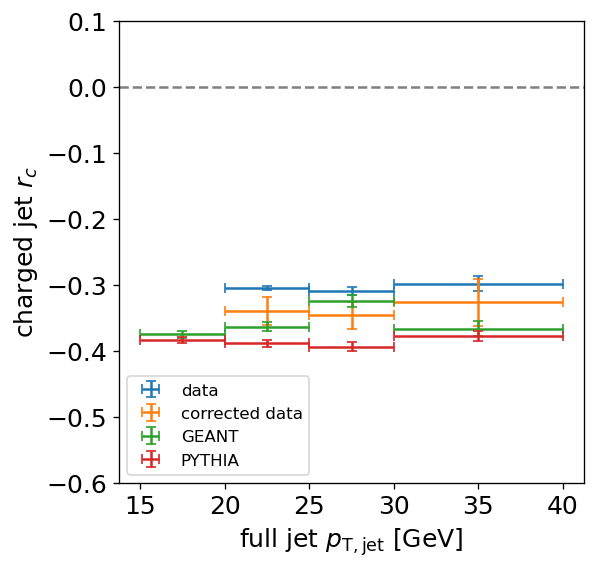

In [34]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], [rcs_0_data, rcs_1_data, rcs_2_data], xerr=[2.5, 2.5, 5], yerr=[rcs_err_0_data, rcs_err_1_data, rcs_err_2_data], capsize=3, ls='none', label='data')
plt.errorbar([22.5, 27.5, 35], rc_corrected, xerr=[2.5, 2.5, 5], yerr=rc_corrected_err, capsize=3, ls='none', label='corrected data')
#plt.errorbar([22.5, 27.5, 35], [-0.3389452430645336,-0.3667611748962564,-0.3263463116487207], xerr=[2.5, 2.5, 5], capsize=3, ls='none', label='corrected data')
#eb1=plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[np.sqrt(rcs_err_0**2+rcs_err_0_sys**2), np.sqrt(rcs_err_1**2+rcs_err_1_sys**2), np.sqrt(rcs_err_2**2+rcs_err_2_sys**2)], capsize=3, color='g', ls='none', label='GEANT')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00, rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, ls='none', label='GEANT')
plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00, rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00, rc_err_0, rc_err_1, rc_err_2], capsize=3, ls='none', label='PYTHIA')
plt.xlabel('full jet $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)

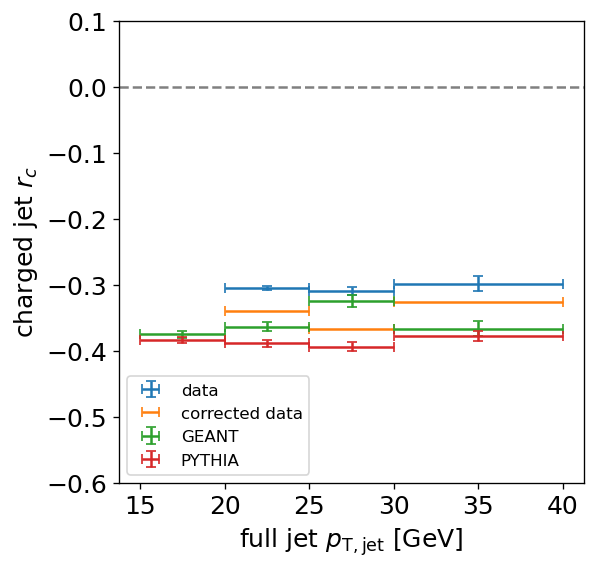

In [34]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], [rcs_0_data, rcs_1_data, rcs_2_data], xerr=[2.5, 2.5, 5], yerr=[rcs_err_0_data, rcs_err_1_data, rcs_err_2_data], capsize=3, ls='none', label='data')
#plt.errorbar([22.5, 27.5, 35], [-0.29835330047997893,-0.323334448845477,-0.23193425739305043], xerr=[2.5, 2.5, 5], capsize=3, ls='none', label='corrected data')
plt.errorbar([22.5, 27.5, 35], [-0.3389452430645336,-0.3667611748962564,-0.3263463116487207], xerr=[2.5, 2.5, 5], capsize=3, ls='none', label='corrected data')
#eb1=plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[np.sqrt(rcs_err_0**2+rcs_err_0_sys**2), np.sqrt(rcs_err_1**2+rcs_err_1_sys**2), np.sqrt(rcs_err_2**2+rcs_err_2_sys**2)], capsize=3, color='g', ls='none', label='GEANT')
plt.errorbar([17.5, 22.5, 27.5, 35], [rcs_00, rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rcs_err_00, rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, ls='none', label='GEANT')
plt.errorbar([17.5, 22.5, 27.5, 35], [rc_00, rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 2.5, 5], yerr=[rc_err_00, rc_err_0, rc_err_1, rc_err_2], capsize=3, ls='none', label='PYTHIA')
plt.xlabel('full jet $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(fontsize=10)